In [1]:
from src.gaussian_mixture import GaussianMixtureMAR
from src.data_generator import DataGenerator
from src.missingness_generator import MissingnessGenerator
from src.utils import true_quantile

import numpy as np
import matplotlib.pyplot as plt
import torch

from src.metrics import energy_distance

from joblib import Parallel, delayed

In [2]:
eps_vals = [0.0, 0.1, 0.3, 0.5, 0.7, 0.9]

In [3]:
n = 2000
d = 3
kk = (1, 20)

In [4]:
k=10
mu0 = torch.rand((k, d)) * 2 - 1 # [-1, 1]
sigma0 = torch.rand((k, d)) * 2 # (0, 2)
pi0 = torch.rand(k) + 0.1
pi0 = pi0 / pi0.sum()

In [5]:
dg = DataGenerator('gaussian_mixture', mu=mu0, sigma=sigma0, pi=pi0)

In [6]:
def run_gaussian_mixture(dg, eps):
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, eps)
    Xtest = dg.sample_truth(n, d)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    return ed, ds

In [7]:
def run_normal(dg, eps):
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, eps)
    Xtest = dg.sample_truth(n, d)
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = gmm.sample(n)[0]
    ed = energy_distance(Xtest, Xtilde).item()
    ds = gmm.evaluate(Xtest).item()
    q1 = np.quantile(Xtilde[:,0], 0.1).item()
    return ed, ds, q1

In [8]:
def run_old(dg, eps, m=20):
    X = dg.sample_truth(n, d)
    M = dg.generate_MNAR1(X, eps)
    Xtest = [dg.sample_truth(n, d) for _ in range(m)]
    gmm = GaussianMixtureMAR(kk)
    gmm.fit(X, M)
    Xtilde = [gmm.sample(n)[0] for _ in range(m)]
    ed = [energy_distance(Xtest[i], Xtilde[i]).item() for i in range(m)]
    ds = [gmm.evaluate(Xtest[i]).item() for i in range(m)]
    return ed, ds

In [9]:
n_runs = 20

In [10]:
results = Parallel(n_jobs=-1)( 
    delayed(run_gaussian_mixture)(dg, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

In [11]:
res = np.array(results).reshape(n_runs, len(eps_vals), 2)

In [18]:
def plot(res, eps):

    color = '#90be6d'

    _, _, m = res.shape
    fig, axes = plt.subplots(1, m, figsize=(14, 4))

    ylabs = ['energy distance', 'density score', 'quantile 0.1']

    for i, ax in enumerate(axes):

        ax.grid(
            True,
            linestyle='--',
            alpha=0.5
        )

        bp = ax.boxplot(
            res[:, :, i],
            patch_artist=True,
            showfliers=False,
            widths=0.3
        )

        ax.set_xticks(
            range(1, len(eps) + 1),
            eps,
            fontsize=11
        )

        ax.set_ylabel(ylabs[i])

        ax.set_xlabel(r'$\epsilon$')

        for patch in bp['boxes']:
            patch.set_facecolor(color)
            patch.set_alpha(0.7)

        # Reference line for subplot 3
        if i == 2:
            ax.axhline(
                #y=-1.282,
                y=-1.282,
                linestyle='--',
                linewidth=1.5
            )

    plt.tight_layout()
    plt.show()

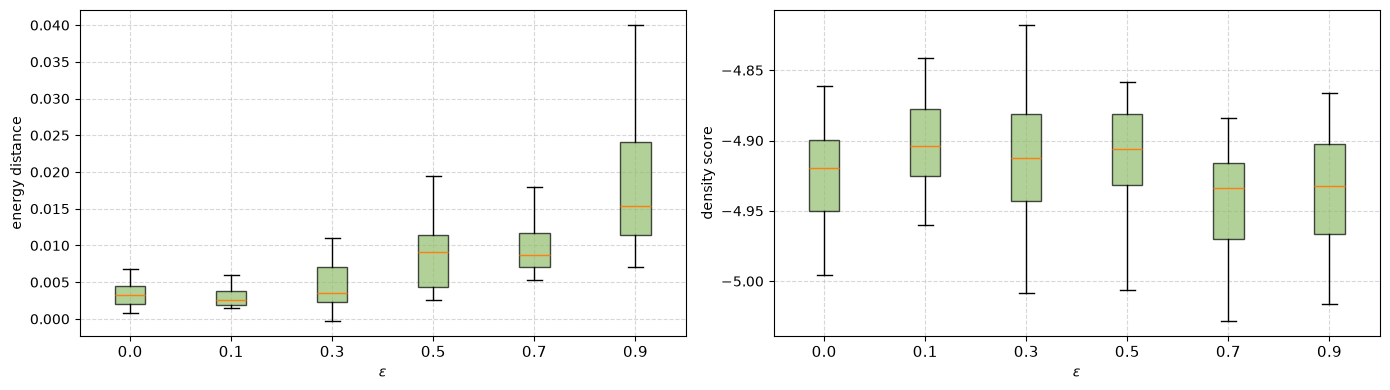

In [13]:
plot(res, eps_vals)

In [14]:
dgn = DataGenerator('Normal')
results_n = Parallel(n_jobs=-1)( 
    delayed(run_normal)(dgn, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

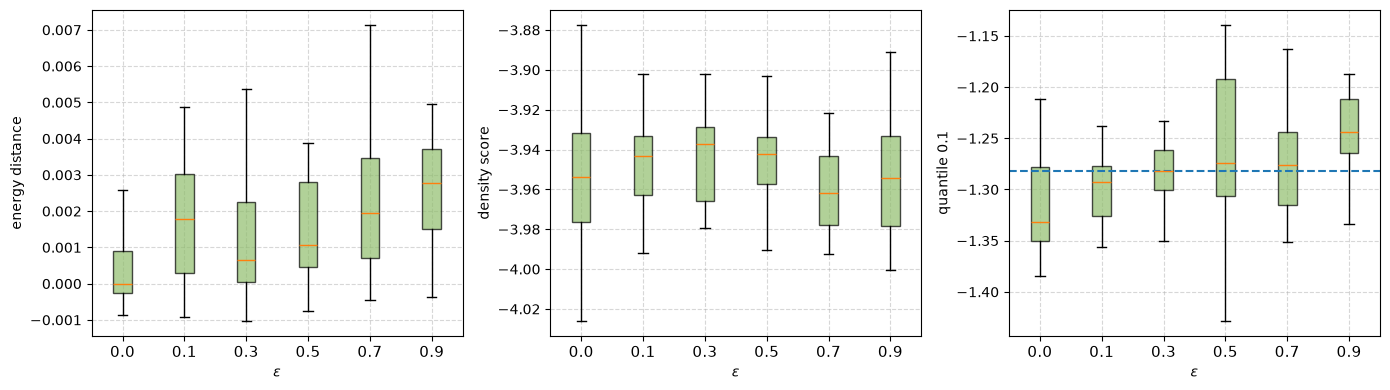

In [19]:
res_n = np.array(results_n).reshape(n_runs, len(eps_vals), 3)
plot(res_n, eps_vals)

In [16]:
dgl = DataGenerator('Logistic')
results_l = Parallel(n_jobs=-1)( 
    delayed(run_normal)(dgl, eps) 
    for _ in range(n_runs) 
    for eps in eps_vals
    )

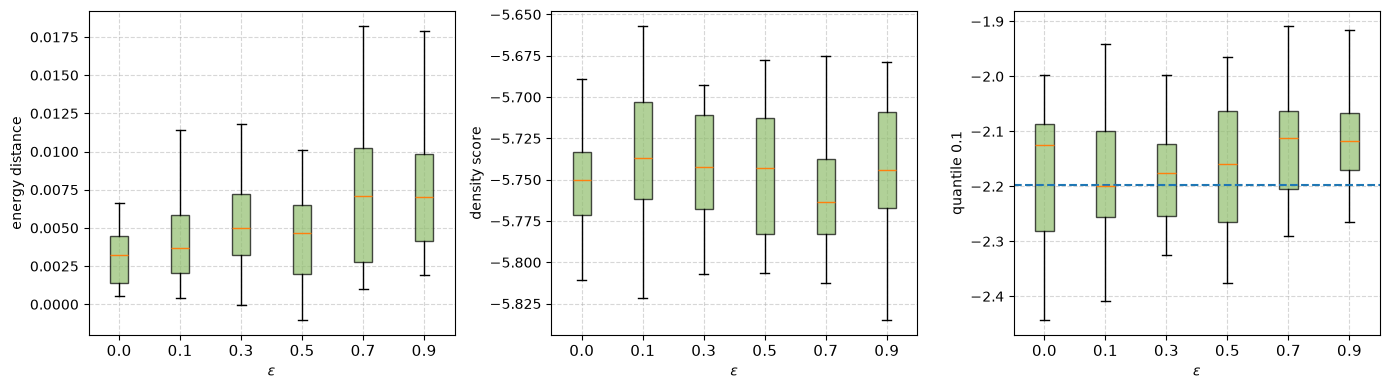

In [17]:
res_l = np.array(results_l).reshape(n_runs, len(eps_vals), 3)
plot(res_l, eps_vals)